# 116 · why each [cls] ablation loses: a root-cause pass over the 200-ep 2×2
Four src9 `transformer2` runs, 200 ep, the same recipe, differing only in how tokens are pooled:

| run | per laser: 18 band tokens → 1 | over lasers: 100 tokens → 1 embedding |
|---|---|---|
| `ref` | gate + flatten + Linear (= 18 separate matrices, one per band) | flatten + Linear(12,800 → 1024) (= 100 separate matrices, one per laser) |
| `freqcls` | **`freq_cls` token** (one shared V for all bands) | flatten (as ref) |
| `lasercls` | gate + flatten (as ref) | **`laser_cls` token** (one shared V for all lasers) |
| `cls` | `freq_cls` | `laser_cls` |

The hypothesis under test: each [cls] swaps **separate weights per position** (per band / per laser) for **one shared value projection**
plus attention that is close to uniform, so positions get folded together. On the frequency side that loses *which band*; on the laser
side it loses *which laser*, i.e. **where** the object is. Each section asks one question, shows the evidence, and says whether it supports
the hypothesis. Everything runs on CPU in fp32 (the GPU is training `freqcls8`), on a few hundred train and eval samples.

In [1]:
import os, sys, math, re
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9, score
from arch.transformer2 import Transformer2
torch.set_num_threads(8); torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 90, "font.size": 10})
RUNS = {"ref": dict(freq_cls=0, laser_cls=0), "freqcls": dict(freq_cls=1, laser_cls=0), "lasercls": dict(freq_cls=0, laser_cls=1), "cls": dict(freq_cls=1, laser_cls=1)}
COL = {"ref": "tab:green", "freqcls": "tab:orange", "lasercls": "tab:blue", "cls": "tab:red"}
name = lambda r: f"s9-t2-{r}-vase-200"
ck8 = ROOT / "runs/s9-t2-freqcls8-vase-200/checkpoints/ep200-ba2000-rank0.pt"
print("freqcls8 (8 freq layers):", "ep200 checkpoint present" if ck8.exists() else "still training: no ep200 checkpoint, left out (pending)")

freqcls8 (8 freq layers): still training: no ep200 checkpoint, left out (pending)


## A · can each model fit the training data, or does it fit but fail to generalize?
From the training logs: the in-distribution (ID) and out-of-distribution (OOD) IoU@.08 at every eval, the training loss, and the
**train-set IoU in eval mode** (logged once at the end on all training samples, no augmentation). If a model's train IoU is also low,
it is **underfitting**: the architecture can't even represent the training data in 200 epochs. If train IoU is high but ID is low,
it **overfits**.

,params,train_IoU,ID,OOD,unseen_pos,gap_train_minus_ID,com_err_train,com_err_ID,final_train_loss
ref,34.9M,0.803,0.679,0.377,0.629,0.124,0.024,0.048,0.233
freqcls,34.6M,0.644,0.561,0.309,0.526,0.083,0.050,0.070,0.490
lasercls,21.9M,0.652,0.541,0.308,0.519,0.111,0.048,0.062,0.448
cls,21.6M,0.412,0.354,0.186,0.329,0.058,0.109,0.116,0.923


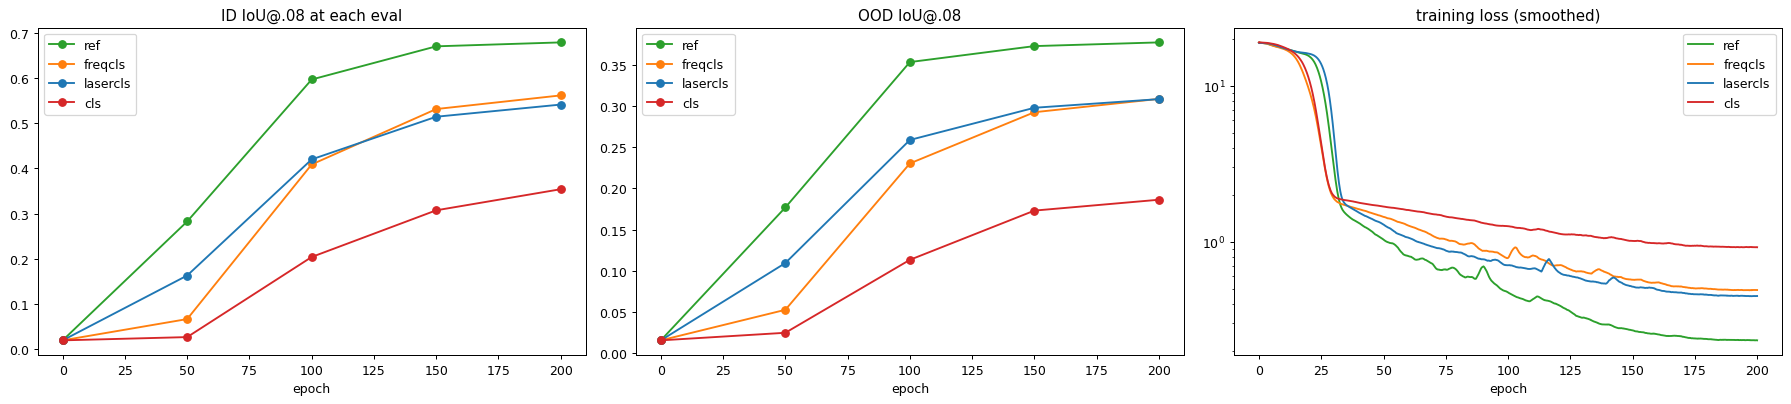

In [2]:
def parse(run):
    txt = (ROOT / "runs" / name(run) / "logs-rank0.txt").read_text()
    curve = lambda k: sorted({int(b) // 10: float(v) for b, v in re.findall(rf"^\[metric\]\[batch=(\d+)\]: {re.escape(k)}: ([0-9.]+)", txt, re.M)}.items())
    last = lambda k: float(re.findall(rf"{re.escape(k)}: ([0-9.]+)", txt)[-1])
    loss = [float(v) for v in re.findall(r"Train loss/train/total: ([0-9.]+)", txt)]
    sd = torch.load(ROOT / f"runs/{name(run)}/checkpoints/ep200-ba2000-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"]
    params = sum(v.numel() for k, v in sd.items() if not any(b in k for b in ("cum_", "running_", "num_batches")))  # weights only, no buffers
    return dict(id=curve("id/iou08"), ood=curve("ood/iou08"), loss=loss, params=params,
                train_iou=last("Eval metrics/train/iou08"), train_com=last("Eval metrics/train/com_err"), train_obj=last("Eval metrics/train/object_acc"),
                id_end=curve("id/iou08")[-1][1], ood_end=curve("ood/iou08")[-1][1], pos=last("metrics/eval/unseen_position/iou08"),
                com_id=curve("id/com_err")[-1][1], com_ood=curve("ood/com_err")[-1][1], obj_id=curve("id/object_acc")[-1][1])
LOG = {r: parse(r) for r in RUNS}
tab = pd.DataFrame({r: dict(params=f"{L['params'] / 1e6:.1f}M", train_IoU=L["train_iou"], ID=L["id_end"], OOD=L["ood_end"], unseen_pos=L["pos"],
                            gap_train_minus_ID=L["train_iou"] - L["id_end"], com_err_train=L["train_com"], com_err_ID=L["com_id"],
                            final_train_loss=np.mean(L["loss"][-20:])) for r, L in LOG.items()}).T
display(tab.style.format({k: "{:.3f}" for k in tab.columns if k != "params"}))

fig, axs = plt.subplots(1, 3, figsize=(20, 4.6))
for r, L in LOG.items():
    e, v = zip(*L["id"]); axs[0].plot(e, v, "o-", color=COL[r], label=r)
    e, v = zip(*L["ood"]); axs[1].plot(e, v, "o-", color=COL[r], label=r)
    s = pd.Series(L["loss"]).rolling(30, min_periods=1).mean(); axs[2].plot(np.arange(len(s)) / 10, s, color=COL[r], label=r)
axs[0].set(title="ID IoU@.08 at each eval", xlabel="epoch"); axs[1].set(title="OOD IoU@.08", xlabel="epoch")
axs[2].set(title="training loss (smoothed)", xlabel="epoch", yscale="log")
for ax in axs: ax.legend()
plt.tight_layout(); plt.show()

## load the four ep200 checkpoints and the samples
The current `transformer2.py` (split flags, no LayerNorm on the `freq_cls` output) is what these runs were trained with, so they load
with `strict=True`. `encode` below is the encoder written out so it can keep every intermediate; it's checked against the real forward.
Samples: 300 **train** samples (with objects), 300 **ID eval** samples (one-object + two-object splits) and 100 **unseen-position** samples.

In [3]:
SD = {r: torch.load(ROOT / f"runs/{name(r)}/checkpoints/ep200-ba2000-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"] for r in RUNS}
NAMES = None
def build(r, sd, freq_layers=2):
    nobj, K = sd["object_head.2.weight"].shape[0], sd["n_objects_head.2.weight"].shape[0] - 1
    info = dict(freq_range=(100.0, 1000.0), n_freqs=1170, n_laser_rows=10, n_laser_cols=10, n_channels=2, boxes=NAMES,
                cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].pow(-2), objects=[str(i) for i in range(nobj + 1)], n_objects=list(range(K + 1)))
    m = Transformer2(info, **RUNS[r], freq_layers=freq_layers)
    m.load_state_dict(sd, strict=True)
    return m.eval()

CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
ev = {"id": [], "unseen-position": []}
for f in sorted((ROOT / f"runs/{name('ref')}/outputs_history/eval").glob("*/*/ep0200-ba*.pt")):
    c = CAT.get((f.parent.parent.name, f.parent.name)); c = "id" if c == "multiple" else c
    if c not in ev: continue
    info = torch.load(f, weights_only=False, map_location="cpu")["info"]
    ev[c] += [(info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) for i in range(len(info["experiment"]))]
samples, idxs = D9.load_splits()
metas = list(samples.values())
tr = [(m["experiment"], int(m["sample_id"]) if m["sample_id"].isdigit() else -1, int(m["position_id"]), int(m["speaker"])) for m in (metas[i] for i in idxs["train"]) if m["n_objects"] > 0]
pick = lambda L, n: [L[i] for i in np.random.choice(len(L), n, replace=False)]
SEL = [("train", s) for s in pick(tr, 300)] + [("id", s) for s in pick(ev["id"], 300)] + [("unseen-position", s) for s in pick(ev["unseen-position"], 100)]
X, BOXN, Y, NOBJ = [], [], [], []
for _, (exp, sid, pos, spk) in SEL:
    d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
    s = D9.load_fft(d, meta, "tukey").abs(); X.append((s / s.std()).float()); BOXN.append(meta["box"]); NOBJ.append(meta["n_objects"])
    Y.append(score.truth(exp, sid, pos, spk, 64, 64))
X, Y, NOBJ = torch.stack(X), np.stack(Y), np.array(NOBJ)
GROUP = np.array([g for g, _ in SEL]); N = len(SEL)
NAMES = sorted(set(BOXN)); BOX = torch.tensor([NAMES.index(b) for b in BOXN])
M = {r: build(r, SD[r]) for r in RUNS}
print("X", tuple(X.shape), {g: int((GROUP == g).sum()) for g in ["train", "id", "unseen-position"]}, "boxes", NAMES)

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400,

X (700, 100, 1170, 2) {'train': 300, 'id': 300, 'unseen-position': 100} boxes ['cardboard', 'gastronorm', 'green-plastic']


In [4]:
def attn(blk, x):
    """attention logits and weights block `blk` uses on input x: (N,H,T,T) each"""
    q, k, _ = blk.qkv(blk.n1(x)).view(*x.shape[:2], 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    lg = q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1]); return lg, lg.softmax(-1)

@torch.no_grad()
def encode(m, x, bx):
    """the transformer2 encoder written out, keeping the intermediates"""
    e, fe, le = m.encoder, m.encoder.freq_enc, m.encoder.laser_enc
    B, L = x.shape[:2]
    xn = e.normalize(x, bx)
    laser = e.laser_emb + e.laser_pos(e.laser_fourier)                                 # (L,128)
    t = fe.embed(xn.reshape(B, L, 18, -1)) + fe.freq_band_emb(e.freq_band_logf[:, None])[None, None] + laser[None, :, None] + fe.box_emb(bx)[:, None, None]
    t = t.flatten(0, 1)
    if fe.cls: t = torch.cat([fe.freq_cls.expand(len(t), 1, -1), t], 1)
    out, FA, FL = dict(energy=xn.reshape(B, L, 18, -1).mean(-1)), [], []
    for blk in fe.freqs:
        lg, a = attn(blk, t); FA.append(a[:, :, 0, 1:]); FL.append(lg[:, :, 0, 1:]); t = blk(t)
    if fe.cls:
        out["freq_attn"] = torch.stack(FA, 1).view(B, L, len(FA), fe.heads, 18)       # what freq_cls reads: (B,L,layers,H,18 bands)
        out["freq_logit_sd"] = torch.stack(FL, 1).std(-1).view(B, L, len(FL), fe.heads)  # spread of its logits over the bands
        raw = t[:, 0].view(B, L, -1)
    else:
        t = t.view(B, L, 18, -1)
        k = fe.pool_k(fe.pool_norm(t)).view(B, L, 18, fe.heads, -1)
        g = torch.einsum("blphe,he->blhp", k, fe.pool_q).div(math.sqrt(k.shape[-1])).softmax(-1).mean(2) * 18
        out["gate"] = g; raw = fe.pool_o((t * g[..., None]).reshape(B, L, -1))
    out["raw"], out["tok"] = raw, raw + laser                                          # per-laser token before / after + laser
    z = out["tok"]
    if le.cls: z = torch.cat([le.laser_cls.expand(B, 1, -1), z], 1)
    LA = []
    for blk in le.lasers:
        _, a = attn(blk, z); LA.append(a[:, :, 0, 1:] if le.cls else a.mean(2)); z = blk(z)  # cls: what laser_cls reads; else: attention each laser receives
    out["laser_attn"] = torch.stack(LA, 1)                                             # (B,layers,H,100)
    out["emb"] = le.to_emb(z[:, 0]) if le.cls else le.to_emb(z)
    out["mask"] = m.decoder(out["emb"])[:, 0].sigmoid()
    return out

def run(m, idx=None, bs=20):
    idx = np.arange(N) if idx is None else idx
    outs = [encode(m, X[idx[i:i + bs]], BOX[idx[i:i + bs]]) for i in range(0, len(idx), bs)]
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}
with torch.no_grad():                                                                  # encode == the real forward
    for r, m in M.items(): assert torch.allclose(m.decoder(m.encoder(X[:4], BOX[:4]))[:, 0].sigmoid(), encode(m, X[:4], BOX[:4])["mask"], atol=1e-5), r
O = {r: run(m) for r, m in M.items()}
def iou(P, idx): return np.mean([((P[i] > .08) & (Y[i] > .5)).sum() / max(((P[i] > .08) | (Y[i] > .5)).sum(), 1) for i in idx])
G = {g: np.where(GROUP == g)[0] for g in ["train", "id", "unseen-position"]}
display(pd.DataFrame({r: {g: iou(O[r]["mask"].numpy(), ix) for g, ix in G.items()} for r in RUNS}).T.style.format("{:.3f}").set_caption("IoU@.08 on these samples (matches the logs?)"))

,train,id,unseen-position
ref,0.819,0.685,0.641
freqcls,0.670,0.553,0.542
lasercls,0.670,0.549,0.535
cls,0.438,0.334,0.351


## B · the frequency side: what does one laser's token still know about its spectrum?
For each run, the 128-d token a laser hands to the laser stage (`raw`, before `+ laser`). Same three tests as nb115, on the 300 ID eval
samples, now on the 200-ep runs (ref and lasercls share the gate + flatten frequency path; freqcls and cls use `freq_cls`):
1. **band-energy probe**: a linear probe from the token to each band's energy (18 targets). Can the token say *which band* was loud?
2. **folding test**: explain the token from the input either with the full band layout (18 × 130 numbers) or with the 130 numbers
   **averaged over bands**. If the token is ≈ "an average over bands", the folded input explains almost all of what the full one does.
3. **how much of the token depends on the sample** (vs being the same for every sample), and how many directions that part uses.

,band_energy_R2,token_R2_full,token_R2_folded,folded_over_full,sample_dep_frac,eff_rank,raw_sample_sd,laser_emb_norm
ref,0.666,0.842,0.100,0.119,0.845,34.538,7.059,4.865
freqcls,0.352,0.380,0.378,0.993,0.430,7.408,3.254,4.827
lasercls,0.584,0.705,0.104,0.147,0.467,19.697,5.731,4.951
cls,0.358,0.281,0.295,1.050,0.178,5.764,2.297,4.936


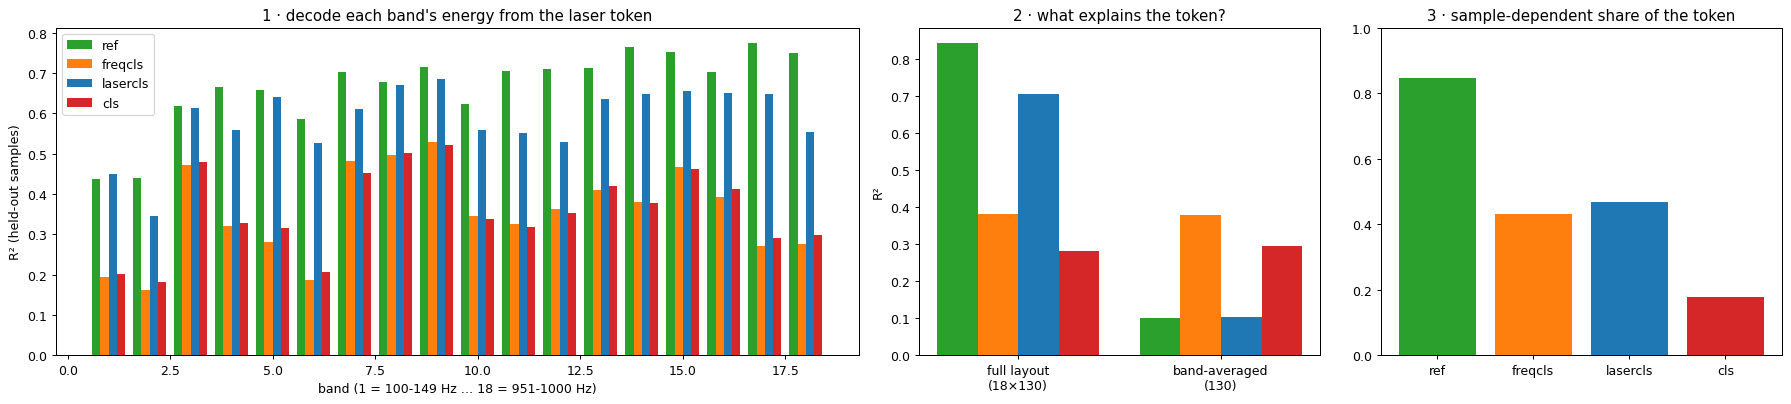

In [5]:
def center(T): return (T - T.mean(0, keepdim=True)).flatten(0, 1).float()
def ridge(Xtr, Ytr, Xte, Yte, lam=1e-2):
    """R² per target on the test rows, standardized ridge"""
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-8; A, Bm = (Xtr - mu) / sd, (Xte - mu) / sd
    w = torch.linalg.solve((A.T @ A).double() + lam * len(A) * torch.eye(A.shape[1], dtype=torch.float64), (A.T @ (Ytr - Ytr.mean(0))).double()).float()
    res = Yte - Ytr.mean(0) - Bm @ w
    return 1 - res.pow(2).sum(0) / (Yte - Yte.mean(0)).pow(2).sum(0)
def probe_rows(Xf, Yf, n_samples):
    """rows are (sample, laser): fit on the first 80% of samples, R² per target on the rest"""
    n = int(n_samples * .8) * 100; return ridge(Xf[:n], Yf[:n], Xf[n:], Yf[n:])
ID = G["id"]
xn_id = M["ref"].encoder.normalize(X[ID], BOX[ID]).reshape(len(ID), 100, 18, 130)     # the input, the same for every run
energy, full, folded = center(xn_id.mean(-1)), center(xn_id.flatten(2)), center(xn_id.mean(2))
B = {}
for r in RUNS:
    tok = center(O[r]["raw"][ID])
    e_r2 = probe_rows(tok, energy, len(ID))                                            # token -> band energies
    f_r2 = probe_rows(full, tok, len(ID)).mean().item()                                # full input -> token
    a_r2 = probe_rows(folded, tok, len(ID)).mean().item()                              # band-averaged input -> token
    T = O[r]["tok"][ID].double(); dev = T - T.mean(0, keepdim=True)
    frac = (dev.pow(2).sum() / (T - T.mean((0, 1), keepdim=True)).pow(2).sum()).item()
    s = torch.linalg.svdvals(dev.flatten(0, 1)) ** 2
    raw = O[r]["raw"][ID]; lsr = (O[r]["tok"][ID] - raw)[0]                          # laser embedding (L,128)
    B[r] = dict(band_energy_R2=e_r2.mean().item(), token_R2_full=f_r2, token_R2_folded=a_r2, folded_over_full=a_r2 / f_r2, sample_dep_frac=frac,
                eff_rank=(s.sum() ** 2 / (s ** 2).sum()).item(), raw_sample_sd=(raw - raw.mean(0)).pow(2).sum(-1).mean().sqrt().item(),
                laser_emb_norm=lsr.norm(dim=-1).mean().item(), e_r2=e_r2)
tb = pd.DataFrame({r: {k: v for k, v in b.items() if k != "e_r2"} for r, b in B.items()}).T
display(tb.style.format("{:.3f}"))
fig, axs = plt.subplots(1, 3, figsize=(20, 4.6), gridspec_kw=dict(width_ratios=[2, 1, 1]))
w = .2
for i, r in enumerate(RUNS): axs[0].bar(np.arange(1, 19) + (i - 1.5) * w, B[r]["e_r2"].numpy(), w, color=COL[r], label=r)
axs[0].set(xlabel="band (1 = 100-149 Hz … 18 = 951-1000 Hz)", ylabel="R² (held-out samples)", title="1 · decode each band's energy from the laser token"); axs[0].legend()
for i, r in enumerate(RUNS): axs[1].bar(np.arange(2) + (i - 1.5) * w, [B[r]["token_R2_full"], B[r]["token_R2_folded"]], w, color=COL[r], label=r)
axs[1].set_xticks(range(2), ["full layout\n(18×130)", "band-averaged\n(130)"]); axs[1].set(title="2 · what explains the token?", ylabel="R²")
axs[2].bar(list(RUNS), [B[r]["sample_dep_frac"] for r in RUNS], color=[COL[r] for r in RUNS]); axs[2].set(title="3 · sample-dependent share of the token", ylim=(0, 1))
plt.tight_layout(); plt.show()

### why is `freq_cls` attention flat? look at the logits, and at what they depend on
`freq_cls` reads the bands through softmax(logits). If the logits barely differ between bands (small spread), the weights are flat no matter
what. Below: the spread (sd over the 18 bands) of the cls row's logits per layer and head, and how far the weights are from uniform.
Then a variance split: does the attention pattern change **between samples** (it reads different bands for different inputs) or only
**between lasers** (a fixed per-laser pattern), or neither?

freqcls: logit sd over bands per (layer, head) [[0.38999998569488525, 0.5600000023841858, 0.1599999964237213, 0.3700000047683716], [0.3499999940395355, 0.28999999165534973, 0.550000011920929, 0.3100000023841858]]
   entropy (1 = uniform) [[0.9599999785423279, 0.9309999942779541, 0.9679999947547913, 0.9319999814033508], [0.9160000085830688, 0.9350000023841858, 0.9150000214576721, 0.9259999990463257]];  max weight [[0.1120000034570694, 0.12399999797344208, 0.07199999690055847, 0.0949999988079071], [0.09000000357627869, 0.08500000089406967, 0.11999999731779099, 0.08699999749660492]] (uniform .056)
   attention variance explained by laser [[0.0, 0.009999999776482582, 0.0, 0.009999999776482582], [0.009999999776482582, 0.009999999776482582, 0.009999999776482582, 0.009999999776482582]], by sample [[0.3499999940395355, 0.18000000715255737, 0.3700000047683716, 0.20000000298023224], [0.3100000023841858, 0.30000001192092896, 0.25, 0.28999999165534973]]
cls: logit sd over bands per (layer, head) [

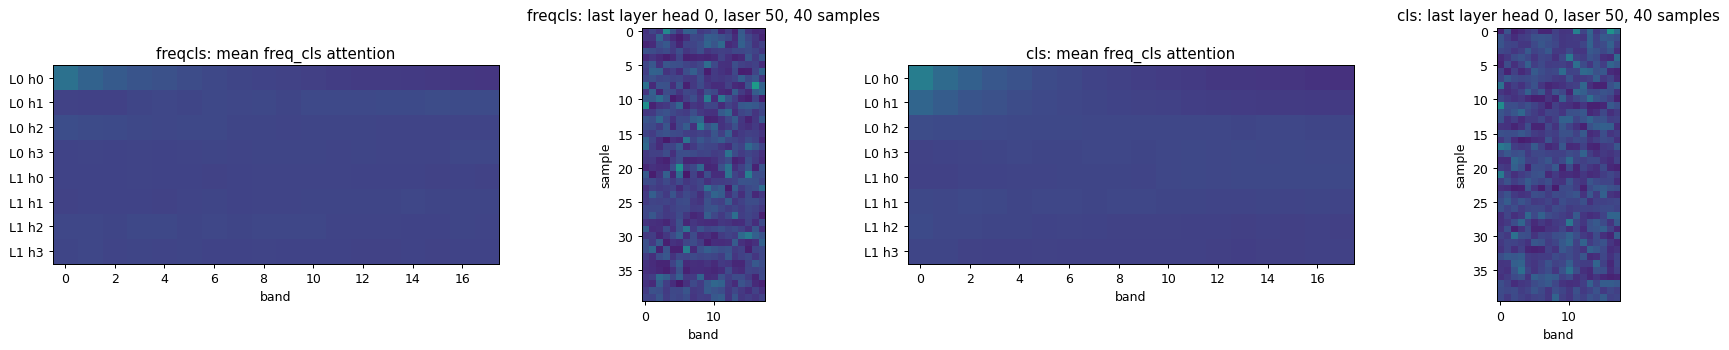

In [6]:
for r in ["freqcls", "cls"]:
    a, lsd = O[r]["freq_attn"][ID], O[r]["freq_logit_sd"][ID]                         # (S,L,layers,H,18), (S,L,layers,H)
    ent = -(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(18)
    tot = a.var((0, 1)).sum(-1)                                                        # (layers,H): total variance over (sample, laser)
    by_laser, by_sample = a.mean(0).var(0).sum(-1), a.mean(1).var(0).sum(-1)
    print(f"{r}: logit sd over bands per (layer, head) {lsd.mean((0, 1)).numpy().round(2).tolist()}")
    print(f"   entropy (1 = uniform) {ent.mean((0, 1)).numpy().round(3).tolist()};  max weight {a.max(-1).values.mean((0, 1)).numpy().round(3).tolist()} (uniform .056)")
    print(f"   attention variance explained by laser {(by_laser / tot).numpy().round(2).tolist()}, by sample {(by_sample / tot).numpy().round(2).tolist()}")
fig, axs = plt.subplots(1, 4, figsize=(20, 4))
for j, r in enumerate(["freqcls", "cls"]):
    a = O[r]["freq_attn"][ID]; nl, nh = a.shape[2:4]
    axs[2 * j].imshow(a.mean((0, 1)).reshape(nl * nh, 18), cmap="viridis", vmin=0, vmax=.25); axs[2 * j].set_title(f"{r}: mean freq_cls attention")
    axs[2 * j].set_yticks(range(nl * nh), [f"L{x} h{y}" for x in range(nl) for y in range(nh)]); axs[2 * j].set_xlabel("band")
    axs[2 * j + 1].imshow(a[:40, 50, -1, 0], cmap="viridis", vmin=0, vmax=.25); axs[2 * j + 1].set(title=f"{r}: last layer head 0, laser 50, 40 samples", xlabel="band", ylabel="sample")
plt.tight_layout(); plt.show()

## C · the laser side: can the final embedding still tell **where** the object is?
The ref's 12,800 × 1024 matrix gives every laser its own block, so "laser 37 changed" and "laser 62 changed" land in different directions
of the embedding. `laser_cls` reads the 100 laser tokens through one shared V. Tests:
1. **CoM probe**: a linear probe from the 1024-d embedding to the object's centre of mass (single-object samples). Fit on train samples,
   tested on ID eval samples (R² and mean error) and on unseen-position samples (mean error only: they all sit in one small square, so R² is meaningless there).
2. **which lasers changed**: a probe from the embedding to the per-laser energy map (100 targets, each laser's mean z-scored input).
3. does the `laser_cls` attention move with the object, or is it a fixed pattern? (variance split + a probe from the attention map to the CoM)

In [7]:
com = np.stack([np.argwhere(y > .5).mean(0) / 64 if (y > .5).any() else [np.nan, np.nan] for y in Y])  # (N,2) row, col in box fractions
one = (NOBJ == 1) & ~np.isnan(com[:, 0])
lmap = O["ref"]["energy"].mean(-1)                                                     # (N,100) each laser's mean z-scored input
lmap = lmap - lmap[G["train"]].mean(0)
def probe(feat, target, tr_idx, te_idx, lams=(1e-3, 1e-2, 1e-1, 1)):
    """ridge from feat to target: pick lambda on a 20% slice of train, refit on all train -> (R² mean over targets, predictions on te_idx)"""
    f, t = torch.as_tensor(feat).float(), torch.as_tensor(target).float()
    n = int(len(tr_idx) * .8); a, b = tr_idx[:n], tr_idx[n:]
    lam = max(lams, key=lambda l: ridge(f[a], t[a], f[b], t[b], l).mean().item())
    mu, sd = f[tr_idx].mean(0), f[tr_idx].std(0) + 1e-8; A = (f[tr_idx] - mu) / sd
    w = torch.linalg.solve((A.T @ A).double() + lam * len(A) * torch.eye(A.shape[1], dtype=torch.float64), (A.T @ (t[tr_idx] - t[tr_idx].mean(0))).double()).float()
    pred = t[tr_idx].mean(0) + ((f[te_idx] - mu) / sd) @ w
    return ridge(f[tr_idx], t[tr_idx], f[te_idx], t[te_idx], lam).mean().item(), pred.numpy()
com_dist = lambda pred, idx: np.linalg.norm(pred - com[idx], axis=1).mean()          # mean CoM error in box fractions
trn, idn, posn = [np.where((GROUP == g) & one)[0] for g in ["train", "id", "unseen-position"]]
C = {}
for r in RUNS:
    emb = O[r]["emb"]
    r2_id, p_id = probe(emb, com, trn, idn); _, p_pos = probe(emb, com, trn, posn)
    C[r] = dict(CoM_R2_ID=r2_id, CoM_probe_err_ID=com_dist(p_id, idn), CoM_probe_err_unseen_pos=com_dist(p_pos, posn),
                laser_map_R2_ID=probe(emb, lmap, G["train"], G["id"])[0], com_err_ID_log=LOG[r]["com_id"], unseen_pos_IoU_log=LOG[r]["pos"])
display(pd.DataFrame(C).T.style.format("{:.3f}"))

,CoM_R2_ID,CoM_probe_err_ID,CoM_probe_err_unseen_pos,laser_map_R2_ID,com_err_ID_log,unseen_pos_IoU_log
ref,0.808,0.100,0.086,0.799,0.048,0.629
freqcls,0.670,0.135,0.126,0.870,0.070,0.526
lasercls,0.819,0.095,0.066,0.604,0.062,0.519
cls,0.576,0.154,0.106,0.800,0.116,0.329


ref per-laser blocks of the 12,800×1024 matrix: mean off-diagonal cosine 0.007 (one shared matrix = 1)
lasercls: laser_cls attention entropy 0.957, max weight 0.039 (uniform .01); distance sample->average map 0.182 vs average->uniform 0.141;  CoM from the attention map: R² ID 0.329, probe CoM error ID 0.199
cls: laser_cls attention entropy 0.907, max weight 0.058 (uniform .01); distance sample->average map 0.278 vs average->uniform 0.206;  CoM from the attention map: R² ID 0.242, probe CoM error ID 0.214


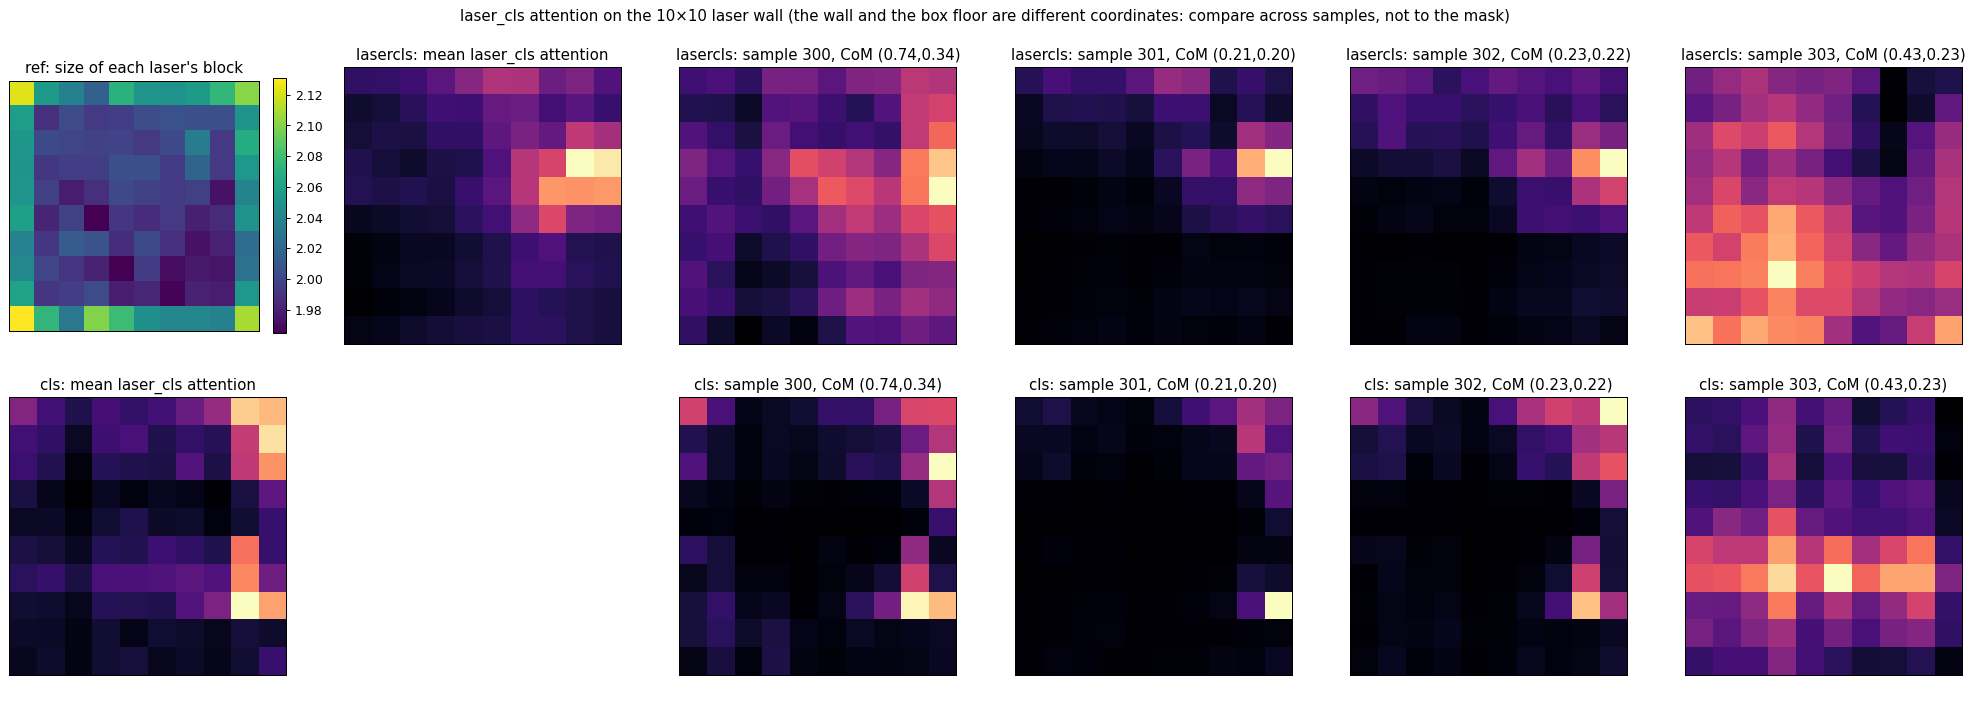

In [8]:
Wl = SD["ref"]["encoder.laser_enc.to_emb.2.weight"].view(1024, 100, 128)
cl = F.normalize(Wl.permute(1, 0, 2).flatten(1), dim=1); cl = cl @ cl.T
print(f"ref per-laser blocks of the 12,800×1024 matrix: mean off-diagonal cosine {cl[~torch.eye(100, dtype=bool)].mean():.3f} (one shared matrix = 1)")
for r in ["lasercls", "cls"]:
    la = O[r]["laser_attn"][:, -1].mean(1)                                            # (N,100) what laser_cls reads, last block, mean over heads
    ent = (-(la * la.clamp_min(1e-12).log()).sum(-1) / math.log(100)).mean()
    tv_sample = (la - la.mean(0)).abs().sum(-1).mean() / 2                             # how far each sample's map is from the average map
    tv_uniform = (la.mean(0) - .01).abs().sum() / 2                                    # how far the average map is from uniform
    print(f"{r}: laser_cls attention entropy {ent:.3f}, max weight {la.max(-1).values.mean():.3f} (uniform .01); "
          f"distance sample->average map {tv_sample:.3f} vs average->uniform {tv_uniform:.3f};  "
          f"CoM from the attention map: R² ID {probe(la, com, trn, idn)[0]:.3f}, probe CoM error ID {com_dist(probe(la, com, trn, idn)[1], idn):.3f}")
fig, axs = plt.subplots(2, 6, figsize=(22, 8))
im = axs[0, 0].imshow(Wl.norm(dim=(0, 2)).view(10, 10), cmap="viridis"); axs[0, 0].set_title("ref: size of each laser's block"); plt.colorbar(im, ax=axs[0, 0], fraction=.046)
for row, r in enumerate(["lasercls", "cls"]):
    la = O[r]["laser_attn"][:, -1].mean(1)
    ax = axs[row, 1] if row == 0 else axs[1, 0]
    ax.imshow(la.mean(0).view(10, 10), cmap="magma"); ax.set_title(f"{r}: mean laser_cls attention")
    for j, i in enumerate(idn[:4]):
        axs[row, 2 + j].imshow(la[i].view(10, 10), cmap="magma"); axs[row, 2 + j].set_title(f"{r}: sample {i}, CoM ({com[i, 0]:.2f},{com[i, 1]:.2f})")
axs[1, 1].axis("off")
for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("laser_cls attention on the 10×10 laser wall (the wall and the box floor are different coordinates: compare across samples, not to the mask)"); plt.tight_layout(); plt.show()

## D · why is both-on worse than the two costs added?
`laser_cls` can only locate the object if the 100 laser tokens it reads **differ from each other in a sample-specific way**: laser 37 must
look different from laser 62 *because of this input*, not just because of its fixed laser embedding. Split each token's sample-dependent
part into (a) what is **common to all lasers** in that sample and (b) what is **laser-specific** (the deviation from that sample's laser average).
Only (b) carries "which laser changed". If `freq_cls` shrinks (b), it starves exactly what `laser_cls` needs.

,laser_specific_share,laser_specific_rms,laser_emb_rms,cos_between_lasers_same_sample,specific_over_laser_emb
ref,0.735,6.053,4.873,0.266,1.242
freqcls,0.430,2.134,4.834,0.577,0.441
lasercls,0.564,4.305,4.959,0.432,0.868
cls,0.391,1.436,4.944,0.615,0.290


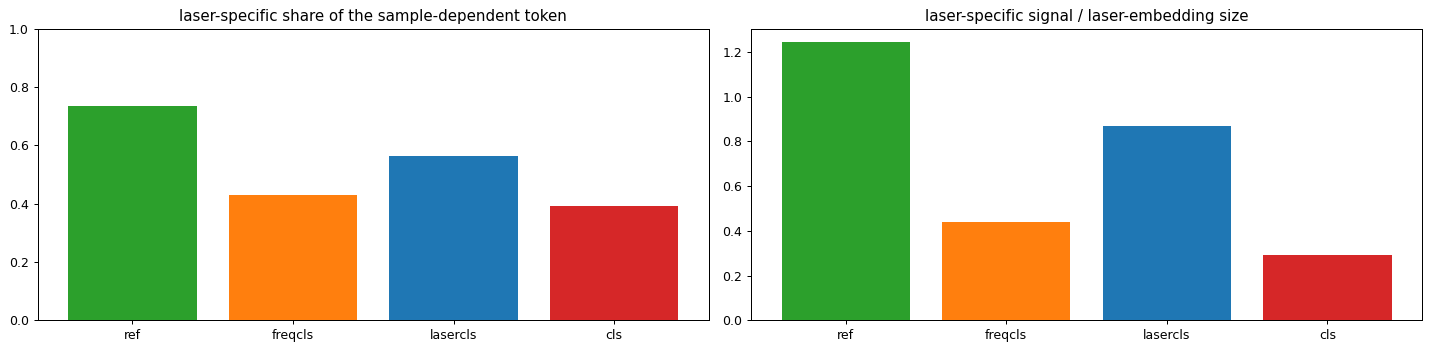

In [9]:
D = {}
for r in RUNS:
    raw = O[r]["raw"][ID].double(); dev = raw - raw.mean(0, keepdim=True)            # sample-dependent part, per laser
    common = dev.mean(1, keepdim=True); spec = dev - common
    lsr = (O[r]["tok"][ID] - O[r]["raw"][ID])[0].double()
    Dn = F.normalize(dev.float(), dim=-1); cosl = torch.einsum("sld,smd->slm", Dn, Dn)
    D[r] = dict(laser_specific_share=(spec.pow(2).sum() / dev.pow(2).sum()).item(),
                laser_specific_rms=spec.pow(2).sum(-1).mean().sqrt().item(), laser_emb_rms=lsr.pow(2).sum(-1).mean().sqrt().item(),
                cos_between_lasers_same_sample=cosl[:, ~torch.eye(100, dtype=bool)].mean().item())
D = pd.DataFrame(D).T; D["specific_over_laser_emb"] = D.laser_specific_rms / D.laser_emb_rms
display(D.style.format("{:.3f}"))
fig, axs = plt.subplots(1, 2, figsize=(16, 4))
axs[0].bar(D.index, D.laser_specific_share, color=[COL[r] for r in D.index]); axs[0].set(title="laser-specific share of the sample-dependent token", ylim=(0, 1))
axs[1].bar(D.index, D.specific_over_laser_emb, color=[COL[r] for r in D.index]); axs[1].set(title="laser-specific signal / laser-embedding size")
plt.tight_layout(); plt.show()

## E · is it just the parameter count?
`lasercls` and `cls` lose ~13M parameters (the 12,800 × 1024 matrix); `freqcls` loses only 0.3M and is the same size as ref.
So the frequency-side loss cannot be a parameter-count effect. On the laser side the two explanations make different predictions:
*capacity* predicts the embedding still holds the location but the smaller model can't use it; *structure* predicts the location is
already missing from the embedding (low CoM probe R²) and from what `laser_cls` attends to.

In [10]:
display(pd.DataFrame({r: dict(params_M=LOG[r]["params"] / 1e6, ID=LOG[r]["id_end"], train_IoU=LOG[r]["train_iou"], CoM_R2_ID=C[r]["CoM_R2_ID"],
                              band_energy_R2=B[r]["band_energy_R2"]) for r in RUNS}).T.style.format("{:.3f}"))

,params_M,ID,train_IoU,CoM_R2_ID,band_energy_R2
ref,34.923,0.679,0.803,0.808,0.666
freqcls,34.611,0.561,0.644,0.670,0.352
lasercls,21.947,0.541,0.652,0.819,0.584
cls,21.635,0.354,0.412,0.576,0.358


## F · other things that matter
**1. learning speed: does the attention sharpen with training?** Compare the ep100 and ep200 checkpoints of the [cls] runs on 100 ID samples:
if the pooling stays flat while the model trains, the bottleneck is structural, not a matter of a few more epochs.

In [11]:
sub = ID[:100]
for r in ["freqcls", "lasercls", "cls"]:
    m100 = build(r, torch.load(ROOT / f"runs/{name(r)}/checkpoints/ep100-ba1000-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"])
    for ep, m in [(100, m100), (200, M[r])]:
        o = run(m, sub); s = f"{r} ep{ep}:"
        if "freq_attn" in o: a = o["freq_attn"]; s += f" freq_cls entropy {(-(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(18)).mean():.3f}, logit sd {o['freq_logit_sd'].mean():.2f};"
        if RUNS[r]["laser_cls"]: la = o["laser_attn"][:, -1].mean(1); s += f" laser_cls entropy {(-(la * la.clamp_min(1e-12).log()).sum(-1) / math.log(100)).mean():.3f};"
        print(s, f"IoU@.08 {np.mean([((o['mask'][j].numpy() > .08) & (Y[i] > .5)).sum() / max(((o['mask'][j].numpy() > .08) | (Y[i] > .5)).sum(), 1) for j, i in enumerate(sub)]):.3f}")
    del m100

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


freqcls ep100: freq_cls entropy 0.936, logit sd 0.37; IoU@.08 0.363


freqcls ep200: freq_cls entropy 0.937, logit sd 0.36; IoU@.08 0.531
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


lasercls ep100: laser_cls entropy 0.959; IoU@.08 0.388


lasercls ep200: laser_cls entropy 0.953; IoU@.08 0.552
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


cls ep100: freq_cls entropy 0.948, logit sd 0.29; laser_cls entropy 0.892; IoU@.08 0.200


cls ep200: freq_cls entropy 0.944, logit sd 0.30; laser_cls entropy 0.898; IoU@.08 0.344


**2. the LayerNorm removal.** The 1000-ep `cls` run had a LayerNorm on the `freq_cls` output; the 200-ep runs don't. Their saved eval
outputs at epoch 200 (same data; the 1000-ep runs are earlier in a longer cosine schedule, so compare each cls run to its own ref).

In [12]:
def idood(run, ep):
    df = score.per_sample(run, ep, .08); c = np.array([CAT.get((b, s)) for b, s in zip(df.box, df.split)])
    return df.iou[np.isin(c, ["id", "multiple"])].mean(), df.iou[np.isin(c, ["rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"])].mean()
ln = pd.DataFrame({k: dict(zip(["ID", "OOD"], idood(*v))) for k, v in {"ref 1k-schedule @ep200": ("s9-t2-ref-vase-1k", 200), "cls 1k-schedule (with LN) @ep200": ("s9-t2-cls-vase-1k", 200),
                                                                     "ref 200-schedule @ep200": (name("ref"), 200), "cls 200-schedule (no LN) @ep200": (name("cls"), 200)}.items()}).T
display(ln.style.format("{:.3f}"))

,ID,OOD
ref 1k-schedule @ep200,0.688,0.376
cls 1k-schedule (with LN) @ep200,0.363,0.205
ref 200-schedule @ep200,0.679,0.377
cls 200-schedule (no LN) @ep200,0.354,0.186


In [13]:
s = lambda r: f"ID {LOG[r]['id_end']:.3f}, train IoU {LOG[r]['train_iou']:.3f}, band-energy R² {B[r]['band_energy_R2']:.3f}, folded/full {B[r]['folded_over_full']:.2f}, CoM R² {C[r]['CoM_R2_ID']:.3f}, laser-map R² {C[r]['laser_map_R2_ID']:.3f}, laser-specific share {D.loc[r, 'laser_specific_share']:.2f}"
for r in RUNS: print(f"{r:9s} {s(r)}")

ref       ID 0.679, train IoU 0.803, band-energy R² 0.666, folded/full 0.12, CoM R² 0.808, laser-map R² 0.799, laser-specific share 0.74
freqcls   ID 0.561, train IoU 0.644, band-energy R² 0.352, folded/full 0.99, CoM R² 0.670, laser-map R² 0.870, laser-specific share 0.43
lasercls  ID 0.541, train IoU 0.652, band-energy R² 0.584, folded/full 0.15, CoM R² 0.819, laser-map R² 0.604, laser-specific share 0.56
cls       ID 0.354, train IoU 0.412, band-energy R² 0.358, folded/full 1.05, CoM R² 0.576, laser-map R² 0.800, laser-specific share 0.39


## summary
**It's a fitting problem, not a generalization problem.** Every [cls] run fits the *training* set worse (train IoU: ref .80, freqcls .64,
lasercls .65, cls .41; train loss .23 / .49 / .45 / .92), and their train − ID gaps are *smaller* than ref's (.12 vs .08 / .11 / .06).
The pooling can't represent what the ref represents, so the eval drop follows the train drop.

**freqcls (ID .56, same params as ref) — the bands get averaged.** The per-laser token is, linearly, a function of the band-averaged spectrum
(folded/full R² .99; ref .12). It decodes each band's energy at R² .35 (ref .67), only 43% of it depends on the sample (ref 85%), and that part
uses ~7 directions (ref ~35). The `freq_cls` attention is flat (entropy .92–.97, logit sd .16–.56), changes between samples but not between
lasers, and does **not sharpen** from ep100 to ep200 (entropy .936 → .937). Same parameter count as ref, so this is structural: one shared V +
flat softmax. What survives is each laser's overall loudness (the embedding still decodes the 10×10 per-laser energy map, R² .87), what's lost
is *which bands* inside a laser.

**lasercls (ID .54, −13M params) — coarse location survives, fine detail doesn't.** Contrary to the hypothesis, the embedding still holds the
object's position as well as ref (CoM probe R² .82 vs .81, probe error .095 vs .100; unseen-position .066 vs .086). What it loses is the
fine per-laser pattern (per-laser energy map R² .60 vs .80) and the ability to fit (train IoU .65). `laser_cls` attention is nearly uniform
(entropy .96, top weight .04 vs .01 uniform), varies by sample, and doesn't sharpen either. Because the 13M-parameter matrix is gone too, this run
can't separate "one shared V" from "fewer parameters".

**cls (ID .35) — the two compound.** `laser_cls` can only tell lasers apart through the part of each token that is specific to that laser in this
sample. `freq_cls` shrinks exactly that part: laser-specific share of the token .74 (ref) → .43 (freqcls) → .39 (cls); laser-specific signal /
laser-embedding size 1.24 → .44 → .29; lasers look alike within a sample (cosine .27 → .58 → .62). So `laser_cls` mostly sees the fixed laser
embedding, and location is lost (CoM R² .58, model com_err .116 vs .048).

**Not the cause:** the LayerNorm removal (the 1k-schedule cls with LN at ep200 is .363 vs .354 without, the same −.009 shift as the refs) and
the gate (ref's gate is ≈ uniform; the 18 separate W_b do the work).

**Limitations, ranked, with the minimal test for each**
1. *Shared V + flat attention over bands* folds the spectrum (−.12 ID at equal params). Test: a per-band embedding `W_x^b` before `freq_cls`
   (untied, ~0.3M params), or k > 1 frequency readout tokens.
2. *Per-laser tokens lose laser-specific contrast* under `freq_cls` (the interaction). Fixed at the source by 1; check the laser-specific share.
3. *`laser_cls` keeps coarse location but loses the fine per-laser pattern*, confounded with −13M params. Test: a per-laser projection before
   `laser_cls` (untied, 100 × 128 × 128 ≈ 1.6M), and a param-matched `laser_cls` (wider laser stage) to split structure from capacity.
4. *Attention never sharpens* (logit sd < .6 at ep100 and ep200). Lower priority: more depth (`freqcls8`, pending) or a learned temperature.